In [ ]:
import pandas as pd
import numpy as np
import re
from urllib.parse import urlparse
import ipaddress

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings("ignore")


In [ ]:
phish_path = "/content/dataset_phishing.csv"
url_path   = "/content/url_features_dataset.csv"

phish_df = pd.read_csv(phish_path, encoding='utf-8', on_bad_lines='skip', dtype=str).copy()
url_df   = pd.read_csv(url_path, encoding='utf-8', on_bad_lines='skip', dtype=str).copy()

print("Phishing dataset shape:", phish_df.shape)
print("URL-features dataset shape:", url_df.shape)

print("\nPhishing dataset columns:", phish_df.columns.tolist())
print("\nURL-features dataset columns:", url_df.columns.tolist())


Phishing dataset shape: (11430, 89)
URL-features dataset shape: (450176, 29)

Phishing dataset columns: ['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 

In [ ]:
# Cleaning & Preparing Data

phish_df['url'] = phish_df['url'].astype(str).str.strip().str.lower()
phish_df.drop_duplicates(subset='url', inplace=True)
phish_df.dropna(subset=['url'], inplace=True)

if 'status' in phish_df.columns:
    phish_df.rename(columns={'status': 'label'}, inplace=True)

phish_df['label'] = phish_df['label'].astype(str).str.lower()
phish_df['label'] = phish_df['label'].replace({
    'bad': 'malicious',
    'phishing': 'malicious',
    'phish': 'malicious',
    'legitimate': 'benign',
    'good': 'benign',
    'safe': 'benign'
})

# Keep only needed final label values
phish_df = phish_df[phish_df['label'].isin(['benign', 'malicious'])]

#Clean URL Features Dataset
url_df['url'] = url_df['url'].astype(str).str.strip().str.lower()
url_df.drop_duplicates(subset='url', inplace=True)
url_df.dropna(subset=['url'], inplace=True)


if 'label' not in url_df.columns:
    url_df['label'] = None  # will be filled later after scoring

print("✅ Cleaning Complete")
print("Remaining | Phishing:", phish_df.shape, "| URL Features:", url_df.shape)


✅ Cleaning Complete
Remaining | Phishing: (11427, 89) | URL Features: (450095, 29)


In [ ]:
# Feature Extraction Function 

def extract_features(url):
    try:
        url = str(url).strip().lower()
        features = {}

        parsed = urlparse(url)

        # Feature: URL Length
        features['length_url'] = len(url)

        # Feature: Hostname Length
        features['length_hostname'] = len(parsed.netloc)

        # Feature: Check if IP present in domain
        try:
            ipaddress.ip_address(parsed.netloc)
            features['ip'] = 1
        except:
            features['ip'] = 0

        # Basic special character counts
        features['nb_dots'] = url.count('.')
        features['nb_hyphens'] = url.count('-')
        features['nb_at'] = url.count('@')
        features['nb_qm'] = url.count('?')
        features['nb_and'] = url.count('&')
        features['nb_or'] = url.count('|')
        features['nb_eq'] = url.count('=')
        features['nb_underscore'] = url.count('_')
        features['nb_percent'] = url.count('%')
        features['nb_slash'] = url.count('/')
        features['nb_dslash'] = url.count('//')

        # HTTPS present in URL
        features['https_token'] = 1 if 'https' in url else 0

        # www count
        features['nb_www'] = url.count("www")

        # .com count
        features['nb_com'] = url.count(".com")

        return features
    except:
        return {}


In [ ]:
# The features you asked to consider for rule-based checks:
rule_features = [
    'url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at',
    'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent',
    'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar',
    'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path'
]

def detect_label_column(df):
    # common candidates
    for c in df.columns:
        if c.lower() in ('label','status','result','is_phishing','class','target'):
            return c
    # fallback: last column
    return df.columns[-1]

# detect labels
label_phish = detect_label_column(phish_df)
label_url   = detect_label_column(url_df)
print("Using label column (phish):", label_phish)
print("Using label column (url)  :", label_url)

def ensure_features(df, features):
    for f in features:
        if f not in df.columns:
            df[f] = 0
    return df

phish_df = ensure_features(phish_df, rule_features)
url_df   = ensure_features(url_df, rule_features)


Using label column (phish): label
Using label column (url)  : label


In [ ]:
import re


def rule_based_scoring(df):
    df = df.copy()
    score = np.zeros(len(df), dtype=int)

    # helper to safely get column (numeric); treat non-numeric as 0
    def get_numeric(col):
        if col in df.columns:
            return pd.to_numeric(df[col], errors='coerce').fillna(0).astype(float)
        return pd.Series(0, index=df.index, dtype=float)

    # thresholds (you can tune these; chosen to be sensible defaults)
    length_url = get_numeric('length_url')
    length_hostname = get_numeric('length_hostname')
    nb_dots = get_numeric('nb_dots')
    nb_hyphens = get_numeric('nb_hyphens')
    nb_at = get_numeric('nb_at')
    nb_qm = get_numeric('nb_qm')
    nb_and = get_numeric('nb_and')
    nb_or = get_numeric('nb_or')
    nb_eq = get_numeric('nb_eq')
    nb_underscore = get_numeric('nb_underscore')
    nb_slash = get_numeric('nb_slash')
    nb_www = get_numeric('nb_www')
    ip = get_numeric('ip')  # 1 if IP present else 0 (some datasets)
    http_in_path = get_numeric('http_in_path')
    nb_percent = get_numeric('nb_percent')
    nb_hyphen = nb_hyphens  # alias
    nb_star = get_numeric('nb_star')
    nb_colon = get_numeric('nb_colon')
    nb_comma = get_numeric('nb_comma')
    nb_semicolumn = get_numeric('nb_semicolumn')
    nb_dollar = get_numeric('nb_dollar')
    nb_space = get_numeric('nb_space')
    nb_www = nb_www
    nb_com = get_numeric('nb_com')
    nb_dslash = get_numeric('nb_dslash')

    # Apply rules - add 1 for each suspicious condition
    score += (length_url > 75).astype(int)
    score += (length_hostname > 30).astype(int)
    score += (nb_dots > 4).astype(int)
    score += (nb_hyphens > 3).astype(int)
    score += (nb_at > 0).astype(int)
    score += (nb_qm > 2).astype(int)
    score += (nb_and > 2).astype(int)
    score += (nb_or > 1).astype(int)
    score += (nb_eq > 3).astype(int)
    score += (nb_underscore > 3).astype(int)
    score += (nb_slash > 10).astype(int)
    score += (ip > 0).astype(int)
    score += (http_in_path > 0).astype(int)
    score += (nb_percent > 2).astype(int)
    score += (nb_star > 0).astype(int)
    score += (nb_colon > 3).astype(int)
    score += (nb_comma > 0).astype(int)
    score += (nb_semicolumn > 0).astype(int)
    score += (nb_dollar > 0).astype(int)
    score += (nb_space > 0).astype(int)
    score += ((nb_www == 0) & (length_hostname>0)).astype(int)  # missing www but long hostname suspicious
    score += (nb_com > 0).astype(int)
    score += (nb_dslash > 3).astype(int)

    df['rule_score'] = score
    df['rule_output'] = (df['rule_score'] >= 4).astype(int)


    if 'url' in df.columns:
        google_safe_mask = df['url'].apply(lambda x: 1 if 'drive.google.com' in str(x).lower() or 'docs.google.com' in str(x).lower() or 'colab.research.google.com' in str(x).lower() else 0)
        df['rule_output'] = df['rule_output'].mask(google_safe_mask == 1, 0)
    return df

phish_df = rule_based_scoring(phish_df)
url_df = rule_based_scoring(url_df)
print("Rule-based outputs added: rule_score, rule_output")

Rule-based outputs added: rule_score, rule_output


In [ ]:
# Statistical method

def statistical_scoring(df, features_for_stat=None):
    df = df.copy()
    if features_for_stat is None:
        features_for_stat = [f for f in rule_features if f in df.columns and f != 'url']

    # ensure numeric
    numeric = df[features_for_stat].apply(pd.to_numeric, errors='coerce').fillna(0)

    # compute per-feature thresholds (mean + std)
    means = numeric.mean()
    stds = numeric.std()
    thresholds = means + stds  # sample threshold

    exceed_count = (numeric > thresholds).sum(axis=1)
    df['stat_exceed_count'] = exceed_count

    df['stat_mean_row'] = numeric.mean(axis=1)
    df['stat_median_row'] = numeric.median(axis=1)
    df['stat_std_row'] = numeric.std(axis=1)

    min_flag_count = max(1, int(0.25 * numeric.shape[1]))
    df['stat_output'] = ((df['stat_exceed_count'] >= min_flag_count) | (df['stat_mean_row'] > numeric.mean().mean() + numeric.std().mean())).astype(int)

    return df, thresholds, means, stds

# Apply to both datasets
url_df, url_thresholds, url_means, url_stds = statistical_scoring(url_df)
phish_df, phish_thresholds, phish_means, phish_stds = statistical_scoring(phish_df)

print("Statistical outputs added: stat_exceed_count, stat_output, stat_mean_row, stat_median_row, stat_std_row")


Statistical outputs added: stat_exceed_count, stat_output, stat_mean_row, stat_median_row, stat_std_row


In [ ]:

#

def prepare_ml_inputs(df, label_col_candidate=None):
    df = df.copy()
    if label_col_candidate is None:
        label_candidates = [c for c in df.columns if c.lower() in ('label','status','result','is_phishing','class','target')]
        label_col = label_candidates[0] if label_candidates else df.columns[-1]
    else:
        label_col = label_col_candidate

    # convert label to numeric if needed
    if df[label_col].dtype == object:
        df[label_col] = df[label_col].astype('category').cat.codes

    # features: numeric columns + rule_output + stat_output
    numeric = df.select_dtypes(include=[np.number]).copy()

    # Ensure rule_output and stat_output are present
    if 'rule_output' not in numeric.columns:
        numeric['rule_output'] = df.get('rule_output', 0).astype(int)
    if 'stat_output' not in numeric.columns:
        numeric['stat_output'] = df.get('stat_output', 0).astype(int)

    # Drop label from numeric if present
    if label_col in numeric.columns:
        numeric = numeric.drop(columns=[label_col])

    X = numeric.copy()
    y = df[label_col].astype(int)
    return X, y, label_col

X_url, y_url, label_url = prepare_ml_inputs(url_df, label_url)
X_phish, y_phish, label_phish = prepare_ml_inputs(phish_df, label_phish)

print("ML inputs prepared:")
print("URL features shape:", X_url.shape, "URL labels shape:", y_url.shape)
print("Phish features shape:", X_phish.shape, "Phish labels shape:", y_phish.shape)


ML inputs prepared:
URL features shape: (450095, 8) URL labels shape: (450095,)
Phish features shape: (11427, 7) Phish labels shape: (11427,)


In [ ]:
# Rule-Based and Statistical accuracy 

from sklearn.metrics import accuracy_score

def compute_rb_st_accuracy(df, label_col):
    """
    df must contain: rule_output, stat_output, and the label column.
    Returns: rb_acc, st_acc (in %)
    """
    # Convert label to numeric if needed
    y_true = df[label_col]
    if y_true.dtype == object:
        y_true = y_true.astype('category').cat.codes

    # Rule-Based accuracy
    if 'rule_output' in df.columns:
        rb_acc = accuracy_score(y_true, df['rule_output']) * 100
    else:
        rb_acc = None

    # Statistical accuracy
    if 'stat_output' in df.columns:
        st_acc = accuracy_score(y_true, df['stat_output']) * 100
    else:
        st_acc = None

    return rb_acc, st_acc


rb_acc_url, st_acc_url = compute_rb_st_accuracy(url_df, label_url)
rb_acc_phish, st_acc_phish = compute_rb_st_accuracy(phish_df, label_phish)

print("✅ Accuracy (Rule vs Statistical)")
print(f"URL Dataset     → Rule: {rb_acc_url:.2f}% | Statistical: {st_acc_url:.2f}%")
print(f"Phishing Dataset→ Rule: {rb_acc_phish:.2f}% | Statistical: {st_acc_phish:.2f}%")


✅ Accuracy (Rule vs Statistical)
URL Dataset     → Rule: 77.77% | Statistical: 75.69%
Phishing Dataset→ Rule: 58.85% | Statistical: 57.89%


In [ ]:

rb_st_features = ['rule_output', 'stat_output', 'rule_score', 'stat_exceed_count',
                  'stat_mean_row', 'stat_median_row', 'stat_std_row']

# Filter only RB+ST columns from original df
X_url_rb_st = url_df[rb_st_features].copy()
X_phish_rb_st = phish_df[rb_st_features].copy()

# Labels
y_url_rb_st = url_df[label_url].astype('category').cat.codes
y_phish_rb_st = phish_df[label_phish].astype('category').cat.codes

print("=== Preparing FULL RB + ST Features for ML ===")
print(f"URL RB+ST Feature Shape: {X_url_rb_st.shape} | Labels: {y_url_rb_st.shape}")
print(f"Phish RB+ST Feature Shape: {X_phish_rb_st.shape} | Labels: {y_phish_rb_st.shape}")


=== Preparing FULL RB + ST Features for ML ===
URL RB+ST Feature Shape: (450095, 7) | Labels: (450095,)
Phish RB+ST Feature Shape: (11427, 7) | Labels: (11427,)



=== Training Models on FULL RB + ST Only ===
Logistic Regression: URL=84.67% | Phish=70.78%
Naive Bayes: URL=74.38% | Phish=59.49%
Random Forest: URL=92.39% | Phish=74.72%

=== Accuracy Comparison: FULL RB + ST Only ===
             Algorithm  URL_Accuracy(%)  Phish_Accuracy(%)
0  Logistic Regression            84.67              70.78
1          Naive Bayes            74.38              59.49
2        Random Forest            92.39              74.72


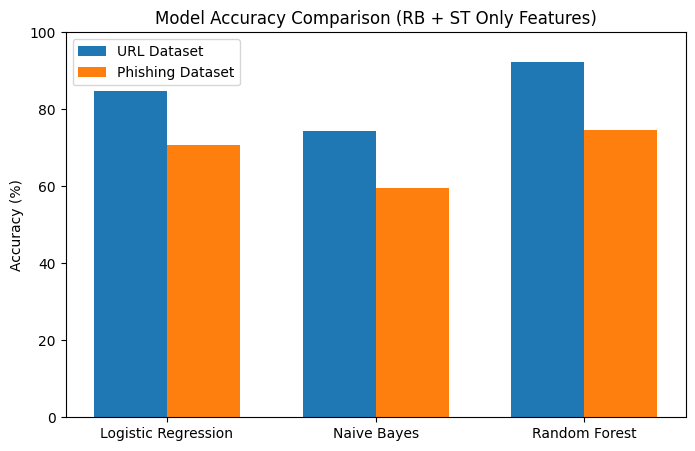

In [ ]:
# Train ML Models

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("\n=== Training Models on FULL RB + ST Only ===")

# 
X_train_url, X_test_url, y_train_url, y_test_url = train_test_split(
    X_url_rb_st, y_url_rb_st, test_size=0.2, random_state=42, shuffle=True
)

X_train_phish, X_test_phish, y_train_phish, y_test_phish = train_test_split(
    X_phish_rb_st, y_phish_rb_st, test_size=0.2, random_state=42, shuffle=True
)

# Model
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, solver='liblinear'),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {"Algorithm": [], "URL_Accuracy(%)": [], "Phish_Accuracy(%)": []}

for name, model in models.items():
    # URL accuracy
    model.fit(X_train_url, y_train_url)
    acc_url = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    # Phish accuracy
    model.fit(X_train_phish, y_train_phish)
    acc_phish = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    results["Algorithm"].append(name)
    results["URL_Accuracy(%)"].append(round(acc_url, 2))
    results["Phish_Accuracy(%)"].append(round(acc_phish, 2))

    print(f"{name}: URL={acc_url:.2f}% | Phish={acc_phish:.2f}%")

# Show Table
df_results_rb_st = pd.DataFrame(results)
print("\n=== Accuracy Comparison: FULL RB + ST Only ===")
print(df_results_rb_st)

# Plot
x = np.arange(len(df_results_rb_st))
width = 0.35
plt.figure(figsize=(8,5))
plt.bar(x - width/2, df_results_rb_st["URL_Accuracy(%)"], width, label="URL Dataset")
plt.bar(x + width/2, df_results_rb_st["Phish_Accuracy(%)"], width, label="Phishing Dataset")
plt.xticks(x, df_results_rb_st["Algorithm"])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison (RB + ST Only Features)")
plt.legend()
plt.show()


In [32]:
# ✅ Minimal Cell: Train LR, NB, RF on RB + ST Features only

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

print("\n=== Training Models on FULL RB + ST Only ===")

# Split
X_train_url, X_test_url, y_train_url, y_test_url = train_test_split(
    X_url_rb_st, y_url_rb_st, test_size=0.2, random_state=42, shuffle=True
)

X_train_phish, X_test_phish, y_train_phish, y_test_phish = train_test_split(
    X_phish_rb_st, y_phish_rb_st, test_size=0.2, random_state=42, shuffle=True
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, solver='liblinear'),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {"Algorithm": [], "URL_Accuracy(%)": [], "Phish_Accuracy(%)": []}

for name, model in models.items():
    # URL
    model.fit(X_train_url, y_train_url)
    acc_url = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    # Phish
    model.fit(X_train_phish, y_train_phish)
    acc_phish = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    results["Algorithm"].append(name)
    results["URL_Accuracy(%)"].append(round(acc_url, 2))
    results["Phish_Accuracy(%)"].append(round(acc_phish, 2))

    print(f"{name}: URL={acc_url:.2f}% | Phish={acc_phish:.2f}%")

print("\n=== Accuracy Comparison: RB + ST Only ===")
print(pd.DataFrame(results))



=== Training Models on FULL RB + ST Only ===
Logistic Regression: URL=84.67% | Phish=70.78%
Naive Bayes: URL=74.38% | Phish=59.49%
Random Forest: URL=92.39% | Phish=74.72%

=== Accuracy Comparison: RB + ST Only ===
             Algorithm  URL_Accuracy(%)  Phish_Accuracy(%)
0  Logistic Regression            84.67              70.78
1          Naive Bayes            74.38              59.49
2        Random Forest            92.39              74.72


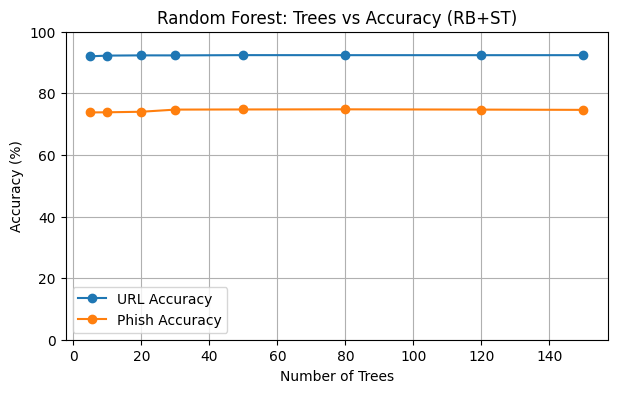

{'Trees': [5, 10, 20, 30, 50, 80, 120, 150],
 'URL_Acc': [92.01501905153357,
  92.24830313600462,
  92.32273186771681,
  92.31495573156778,
  92.40049322920717,
  92.38938446327998,
  92.3849409569091,
  92.38827358668725],
 'Phish_Acc': [73.79702537182851,
  73.84076990376202,
  74.01574803149606,
  74.71566054243219,
  74.7594050743657,
  74.80314960629921,
  74.71566054243219,
  74.62817147856518]}

In [33]:
# --- RANDOM FOREST: Trees vs Accuracy (RB + ST Only) ---

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

tree_counts = [5, 10, 20, 30, 50, 80, 120, 150]

rf_results = {"Trees": [], "URL_Acc": [], "Phish_Acc": []}

for n in tree_counts:
    model = RandomForestClassifier(n_estimators=n, random_state=42)

    # URL
    model.fit(X_train_url, y_train_url)
    acc_url = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    # Phish
    model.fit(X_train_phish, y_train_phish)
    acc_phish = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    rf_results["Trees"].append(n)
    rf_results["URL_Acc"].append(acc_url)
    rf_results["Phish_Acc"].append(acc_phish)

plt.figure(figsize=(7,4))
plt.plot(rf_results["Trees"], rf_results["URL_Acc"], marker='o', label="URL Accuracy")
plt.plot(rf_results["Trees"], rf_results["Phish_Acc"], marker='o', label="Phish Accuracy")
plt.xlabel("Number of Trees")
plt.ylabel("Accuracy (%)")
plt.title("Random Forest: Trees vs Accuracy (RB+ST)")
plt.grid(True)
plt.legend()
plt.ylim(0,100)
plt.show()

rf_results


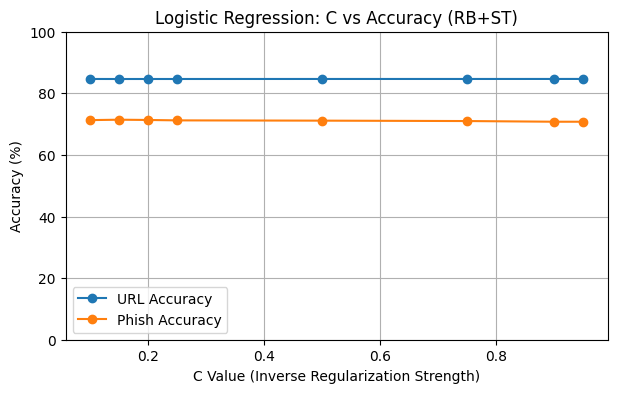

{'C': [0.1, 0.15, 0.2, 0.25, 0.5, 0.75, 0.9, 0.95],
 'URL_Acc': [84.65990513113898,
  84.64879636521178,
  84.65212899498995,
  84.65323987158267,
  84.65990513113898,
  84.65990513113898,
  84.66323776091714,
  84.66879214388074],
 'Phish_Acc': [71.30358705161855,
  71.43482064741907,
  71.34733158355205,
  71.21609798775154,
  71.12860892388451,
  70.99737532808399,
  70.77865266841646,
  70.77865266841646]}

In [ ]:
# LOGISTIC REGRESSION:

from sklearn.linear_model import LogisticRegression

c_values = [0.1,0.15,0.2, 0.25, 0.5, 0.75, 0.9, 0.95]

lr_results = {"C": [], "URL_Acc": [], "Phish_Acc": []}

for c in c_values:
    model = LogisticRegression(C=c, max_iter=1000, solver='liblinear')

    # URL
    model.fit(X_train_url, y_train_url)
    acc_url = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    # Phish
    model.fit(X_train_phish, y_train_phish)
    acc_phish = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    lr_results["C"].append(c)
    lr_results["URL_Acc"].append(acc_url)
    lr_results["Phish_Acc"].append(acc_phish)

plt.figure(figsize=(7,4))
plt.plot(lr_results["C"], lr_results["URL_Acc"], marker='o', label="URL Accuracy")
plt.plot(lr_results["C"], lr_results["Phish_Acc"], marker='o', label="Phish Accuracy")
plt.xlabel("C Value (Inverse Regularization Strength)")
plt.ylabel("Accuracy (%)")
plt.title("Logistic Regression: C vs Accuracy (RB+ST)")
plt.grid(True)
plt.ylim(0,100)
plt.legend()
plt.show()

lr_results


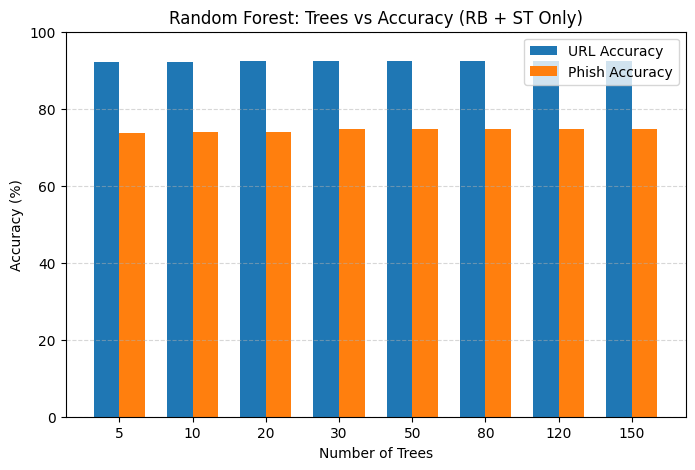

{'Trees': [5, 10, 20, 30, 50, 80, 120, 150],
 'URL_Acc': [92.01501905153357,
  92.24830313600462,
  92.32273186771681,
  92.31495573156778,
  92.40049322920717,
  92.38938446327998,
  92.3849409569091,
  92.38827358668725],
 'Phish_Acc': [73.79702537182851,
  73.84076990376202,
  74.01574803149606,
  74.71566054243219,
  74.7594050743657,
  74.80314960629921,
  74.71566054243219,
  74.62817147856518]}

In [ ]:
# RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

tree_counts = [5, 10, 20, 30, 50, 80, 120, 150]

rf_results = {"Trees": [], "URL_Acc": [], "Phish_Acc": []}

for n in tree_counts:
    model = RandomForestClassifier(n_estimators=n, random_state=42)

    # URL
    model.fit(X_train_url, y_train_url)
    acc_url = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    # Phish
    model.fit(X_train_phish, y_train_phish)
    acc_phish = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    rf_results["Trees"].append(n)
    rf_results["URL_Acc"].append(acc_url)
    rf_results["Phish_Acc"].append(acc_phish)

# ---- BAR GRAPH ----
x = np.arange(len(tree_counts))   # x positions for groups
width = 0.35                      # bar width

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, rf_results["URL_Acc"], width, label='URL Accuracy')
plt.bar(x + width/2, rf_results["Phish_Acc"], width, label='Phish Accuracy')

plt.xticks(x, tree_counts)
plt.xlabel("Number of Trees")
plt.ylabel("Accuracy (%)")
plt.title("Random Forest: Trees vs Accuracy (RB + ST Only)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.ylim(0, 100)
plt.show()

rf_results


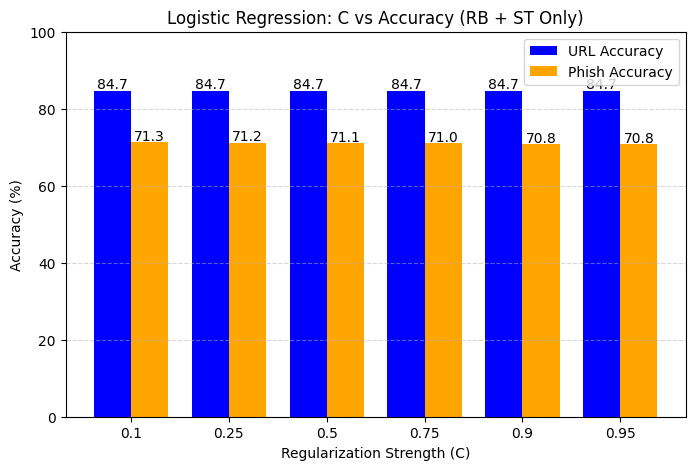

In [ ]:
#  LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

C_values =[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]

url_acc = []
phish_acc = []

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000, solver='liblinear')

    model.fit(X_train_url, y_train_url)
    url_score = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    model.fit(X_train_phish, y_train_phish)
    phish_score = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    url_acc.append(url_score)
    phish_acc.append(phish_score)

x = np.arange(len(C_values))
width = 0.38

plt.figure(figsize=(8,5))
bars1 = plt.bar(x - width/2, url_acc, width, label='URL Accuracy', color='blue')
bars2 = plt.bar(x + width/2, phish_acc, width, label='Phish Accuracy', color='orange')

# Value labels
for bar in bars1:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5, f"{bar.get_height():.1f}", ha='center')
for bar in bars2:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5, f"{bar.get_height():.1f}", ha='center')

plt.xticks(x, C_values)
plt.xlabel("Regularization Strength (C)")
plt.ylabel("Accuracy (%)")
plt.title("Logistic Regression: C vs Accuracy (RB + ST Only)")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


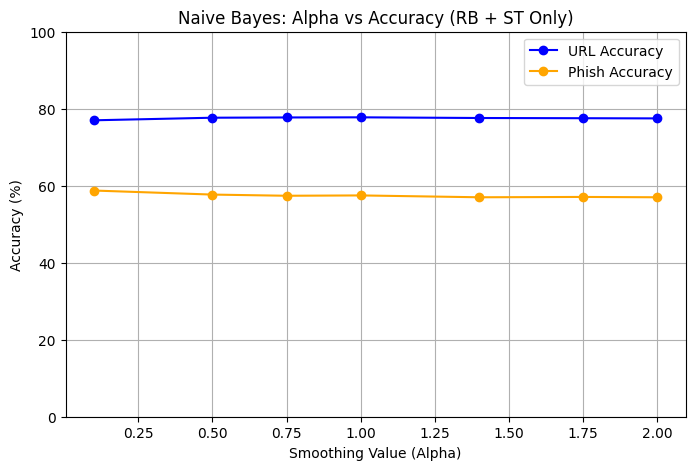

In [ ]:
#  NAIVE BAYES: Alpha vs Accuracy 

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

alpha_values = [0.1,0.5,0.75,1.0,1.4,1.75,2.0]
url_acc = []
phish_acc = []

for a in alpha_values:
    model = GaussianNB(var_smoothing=a)

    model.fit(X_train_url, y_train_url)
    url_score = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    model.fit(X_train_phish, y_train_phish)
    phish_score = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    url_acc.append(url_score)
    phish_acc.append(phish_score)

plt.figure(figsize=(8,5))
plt.plot(alpha_values, url_acc, marker='o', label='URL Accuracy', color='blue')
plt.plot(alpha_values, phish_acc, marker='o', label='Phish Accuracy', color='orange')

plt.xlabel("Smoothing Value (Alpha)")
plt.ylabel("Accuracy (%)")
plt.title("Naive Bayes: Alpha vs Accuracy (RB + ST Only)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.show()


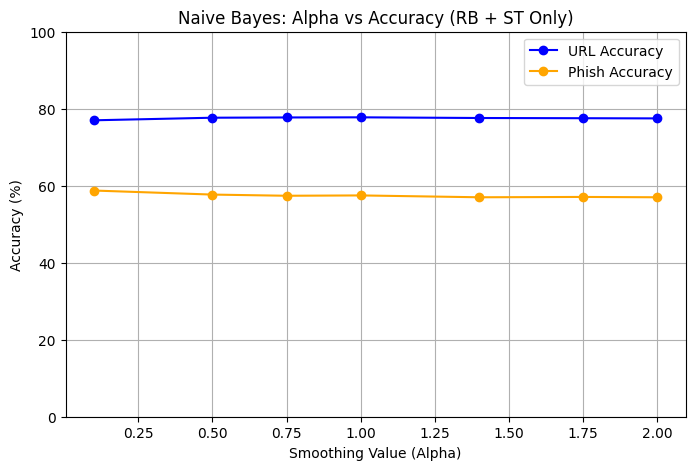

In [ ]:
#  NAIVE BAYES: Alpha vs Accuracy

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

alpha_values = [0.1,0.5,0.75,1.0,1.4,1.75,2.0]
url_acc = []
phish_acc = []

for a in alpha_values:
    model = GaussianNB(var_smoothing=a)

    model.fit(X_train_url, y_train_url)
    url_score = accuracy_score(y_test_url, model.predict(X_test_url)) * 100

    model.fit(X_train_phish, y_train_phish)
    phish_score = accuracy_score(y_test_phish, model.predict(X_test_phish)) * 100

    url_acc.append(url_score)
    phish_acc.append(phish_score)

plt.figure(figsize=(8,5))
plt.plot(alpha_values, url_acc, marker='o', label='URL Accuracy', color='blue')
plt.plot(alpha_values, phish_acc, marker='o', label='Phish Accuracy', color='orange')

plt.xlabel("Smoothing Value (Alpha)")
plt.ylabel("Accuracy (%)")
plt.title("Naive Bayes: Alpha vs Accuracy (RB + ST Only)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.show()


In [ ]:


from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import joblib
import warnings
warnings.filterwarnings("ignore")

print("Training models on URL dataset (RB+ST)...")
rf_url_model = RandomForestClassifier(n_estimators=100, random_state=42)
lr_url_model = LogisticRegression(max_iter=1000, solver='liblinear')
nb_url_model = GaussianNB()

rf_url_model.fit(X_train_url, y_train_url)
lr_url_model.fit(X_train_url, y_train_url)
nb_url_model.fit(X_train_url, y_train_url)

print("URL models trained.")
print("  URL RF accuracy:  {:.2f}%".format(accuracy_score(y_test_url, rf_url_model.predict(X_test_url)) * 100))
print("  URL LR accuracy:  {:.2f}%".format(accuracy_score(y_test_url, lr_url_model.predict(X_test_url)) * 100))
print("  URL NB accuracy:  {:.2f}%".format(accuracy_score(y_test_url, nb_url_model.predict(X_test_url)) * 100))


print("\nTraining models on Phishing dataset (RB+ST)...")
rf_phish_model = RandomForestClassifier(n_estimators=100, random_state=42)
lr_phish_model = LogisticRegression(max_iter=1000, solver='liblinear')
nb_phish_model = GaussianNB()

rf_phish_model.fit(X_train_phish, y_train_phish)
lr_phish_model.fit(X_train_phish, y_train_phish)
nb_phish_model.fit(X_train_phish, y_train_phish)

print("Phish models trained.")
print("  Phish RF accuracy: {:.2f}%".format(accuracy_score(y_test_phish, rf_phish_model.predict(X_test_phish)) * 100))
print("  Phish LR accuracy: {:.2f}%".format(accuracy_score(y_test_phish, lr_phish_model.predict(X_test_phish)) * 100))
print("  Phish NB accuracy: {:.2f}%".format(accuracy_score(y_test_phish, nb_phish_model.predict(X_test_phish)) * 100))


# === Save Models in Joblib Format ===
joblib.dump(rf_url_model,   "rf_url_model.joblib")
joblib.dump(lr_url_model,   "lr_url_model.joblib")
joblib.dump(nb_url_model,   "nb_url_model.joblib")

joblib.dump(rf_phish_model, "rf_phish_model.joblib")
joblib.dump(lr_phish_model, "lr_phish_model.joblib")
joblib.dump(nb_phish_model, "nb_phish_model.joblib")

print("\n✅ All 6 models saved as .joblib files successfully!")


Training models on URL dataset (RB+ST)...
URL models trained.
  URL RF accuracy:  92.39%
  URL LR accuracy:  84.67%
  URL NB accuracy:  74.38%

Training models on Phishing dataset (RB+ST)...
Phish models trained.
  Phish RF accuracy: 74.72%
  Phish LR accuracy: 70.78%
  Phish NB accuracy: 59.49%

✅ All 6 models saved as .joblib files successfully!


In [ ]:
import pandas as pd
import numpy as np
import joblib

sample_url = "http://example.com/malicious/login.php?user=admin&pass=123"

sample_features = extract_features(sample_url)
sample_df = pd.DataFrame([sample_features])


def ensure_features_for_single_url(df, features):
    for f in features:
        if f not in df.columns:
            df[f] = 0
    # Ensure all are numeric
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    return df

sample_df = ensure_features_for_single_url(sample_df, rule_features)

sample_df = rule_based_scoring(sample_df)


numeric_sample = sample_df[url_means.index].apply(pd.to_numeric, errors='coerce').fillna(0)

# Calculate exceed count using global thresholds
exceed_count = (numeric_sample > url_thresholds.to_frame().T).sum(axis=1)
sample_df['stat_exceed_count'] = exceed_count

# Calculate stat_mean_row, stat_median_row, stat_std_row
sample_df['stat_mean_row'] = numeric_sample.mean(axis=1)
sample_df['stat_median_row'] = numeric_sample.median(axis=1)
sample_df['stat_std_row'] = numeric_sample.std(axis=1)

min_flag_count = max(1, int(0.25 * numeric_sample.shape[1])) 
sample_df['stat_output'] = ((sample_df['stat_exceed_count'] >= min_flag_count) |
                            (sample_df['stat_mean_row'] > url_means.mean() + url_stds.mean())).astype(int)

# Prepare features for ML models ---
rb_st_features = ['rule_output', 'stat_output', 'rule_score', 'stat_exceed_count',
                  'stat_mean_row', 'stat_median_row', 'stat_std_row']

X_sample = sample_df[rb_st_features]

print(f"Testing URL: {sample_url}\n")

print("--- Predictions using URL Dataset Models ---")
print(f"Random Forest (URL): {rf_url_model.predict(X_sample)[0]} (0: Benign, 1: Malicious)")
print(f"Logistic Regression (URL): {lr_url_model.predict(X_sample)[0]} (0: Benign, 1: Malicious)")
print(f"Naive Bayes (URL): {nb_url_model.predict(X_sample)[0]} (0: Benign, 1: Malicious)\n")

print("--- Predictions using Phishing Dataset Models ---")
print(f"Random Forest (Phish): {rf_phish_model.predict(X_sample)[0]} (0: Benign, 1: Malicious)")
print(f"Logistic Regression (Phish): {lr_phish_model.predict(X_sample)[0]} (0: Benign, 1: Malicious)")
print(f"Naive Bayes (Phish): {nb_phish_model.predict(X_sample)[0]} (0: Benign, 1: Malicious)")


Testing URL: http://example.com/malicious/login.php?user=admin&pass=123

--- Predictions using URL Dataset Models ---
Random Forest (URL): 1 (0: Benign, 1: Malicious)
Logistic Regression (URL): 1 (0: Benign, 1: Malicious)
Naive Bayes (URL): 0 (0: Benign, 1: Malicious)

--- Predictions using Phishing Dataset Models ---
Random Forest (Phish): 0 (0: Benign, 1: Malicious)
Logistic Regression (Phish): 0 (0: Benign, 1: Malicious)
Naive Bayes (Phish): 0 (0: Benign, 1: Malicious)


### Train ML Models on ALL Numeric Features


=== Training Models on ALL Numeric Features ===
Logistic Regression: URL=84.67% | Phish=70.78%
Naive Bayes: URL=74.38% | Phish=59.49%
Random Forest: URL=92.37% | Phish=74.50%

=== Accuracy Comparison: ALL Numeric Features ===
             Algorithm  URL_Accuracy(%)  Phish_Accuracy(%)
0  Logistic Regression            84.67              70.78
1          Naive Bayes            74.38              59.49
2        Random Forest            92.37              74.50


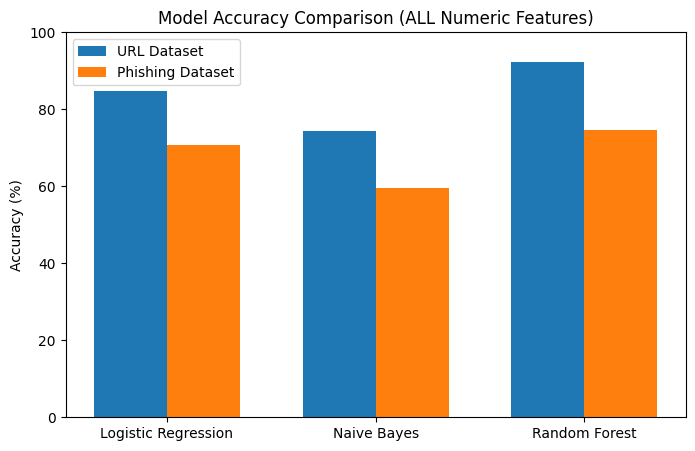

In [ ]:

X_train_url_all, X_test_url_all, y_train_url_all, y_test_url_all = train_test_split(
    X_url, y_url, test_size=0.2, random_state=42, shuffle=True
)

X_train_phish_all, X_test_phish_all, y_train_phish_all, y_test_phish_all = train_test_split(
    X_phish, y_phish, test_size=0.2, random_state=42, shuffle=True
)

print("\n=== Training Models on ALL Numeric Features ===")

results_all_features = {"Algorithm": [], "URL_Accuracy(%)": [], "Phish_Accuracy(%)": []}

for name, model in models.items(): # Re-using the 'models' dictionary defined earlier
    # URL dataset with ALL features
    model.fit(X_train_url_all, y_train_url_all)
    acc_url_all = accuracy_score(y_test_url_all, model.predict(X_test_url_all)) * 100

    # Phishing dataset with ALL features
    model.fit(X_train_phish_all, y_train_phish_all)
    acc_phish_all = accuracy_score(y_test_phish_all, model.predict(X_test_phish_all)) * 100

    results_all_features["Algorithm"].append(name)
    results_all_features["URL_Accuracy(%)"].append(round(acc_url_all, 2))
    results_all_features["Phish_Accuracy(%)"].append(round(acc_phish_all, 2))

    print(f"{name}: URL={acc_url_all:.2f}% | Phish={acc_phish_all:.2f}%")

df_results_all_features = pd.DataFrame(results_all_features)
print("\n=== Accuracy Comparison: ALL Numeric Features ===")
print(df_results_all_features)

# Plotting the results for comparison
x = np.arange(len(df_results_all_features))
width = 0.35
plt.figure(figsize=(8,5))
plt.bar(x - width/2, df_results_all_features["URL_Accuracy(%)"], width, label="URL Dataset")
plt.bar(x + width/2, df_results_all_features["Phish_Accuracy(%)"], width, label="Phishing Dataset")
plt.xticks(x, df_results_all_features["Algorithm"])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison (ALL Numeric Features)")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import joblib
import re

# --- Step 1: Define a sample URL for testing ---
sample_url = input("Enter the URL you want to test: ")

# --- Step 2: Extract features for the sample URL ---
sample_features = extract_features(sample_url)
sample_df = pd.DataFrame([sample_features])

# --- Step 3: Ensure all rule_features exist and convert to numeric ---
def ensure_features_for_single_url(df, features):
    for f in features:
        if f not in df.columns:
            df[f] = 0
    # Ensure all are numeric
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    return df

sample_df = ensure_features_for_single_url(sample_df, rule_features)

# --- Step 4: Apply Rule-based Scoring ---
def rule_based_scoring_detailed(df):
    df = df.copy()
    score = np.zeros(len(df), dtype=int)
    rule_reasons_list = [] # List to store reasons for each URL

    def get_numeric(col):
        if col in df.columns:
            return pd.to_numeric(df[col], errors='coerce').fillna(0).astype(float)
        return pd.Series(0, index=df.index, dtype=float)

    length_url = get_numeric('length_url')
    nb_dots = get_numeric('nb_dots')
    nb_hyphens = get_numeric('nb_hyphens')
    nb_at = get_numeric('nb_at')
    ip = get_numeric('ip')
    nb_qm = get_numeric('nb_qm')
    nb_and = get_numeric('nb_and')
    nb_or = get_numeric('nb_or')
    nb_eq = get_numeric('nb_eq')
    nb_underscore = get_numeric('nb_underscore')
    nb_slash = get_numeric('nb_slash')
    nb_star = get_numeric('nb_star')
    nb_colon = get_numeric('nb_colon')
    nb_comma = get_numeric('nb_comma')
    nb_semicolumn = get_numeric('nb_semicolumn')
    nb_dollar = get_numeric('nb_dollar')
    nb_space = get_numeric('nb_space')
    nb_www = get_numeric('nb_www')
    nb_com = get_numeric('nb_com')
    nb_dslash = get_numeric('nb_dslash')
    http_in_path = get_numeric('http_in_path')
    nb_percent = get_numeric('nb_percent')
    length_hostname = get_numeric('length_hostname')

    # List of keywords that often indicate suspicious activity
    unsafe_keywords = ['login', 'verify', 'account', 'update', 'banking', 'secure', 'paypal', 'webscr', 'confirm', 'billing', 'signin', 'suspended', 'alert', 'error', 'activity', 'authenticate', 'personal', 'information', 'password', 'credential', 'free', 'gift', 'prize', 'winner', 'click', 'urgent', 'epass', 'admin', 'oauth', 'token', 'access', 'confirm_id', 'id_verification', 'security_check']

    # Apply rules - add 1 for each suspicious condition and collect reasons
    for index, row in df.iterrows():
        reasons = []
        current_score = 0

        # Check for suspicious keywords
        url_lower = str(row['url']).lower()
        for keyword in unsafe_keywords:
            if keyword in url_lower:
                current_score += 2  # Changed from +1 to +2 as per user request
                reasons.append(f"Suspicious keyword '{keyword}' detected in URL.")
                # Only count one reason per keyword type, but continue checking for other keywords

        if length_url.iloc[index] > 75:
            current_score += 1
            reasons.append(f"length_url ({length_url.iloc[index]}) > 75")
        if length_hostname.iloc[index] > 30:
            current_score += 1
            reasons.append(f"length_hostname ({length_hostname.iloc[index]}) > 30")
        if nb_dots.iloc[index] > 4:
            current_score += 1
            reasons.append(f"nb_dots ({nb_dots.iloc[index]}) > 4")
        if nb_hyphens.iloc[index] > 3:
            current_score += 1
            reasons.append(f"nb_hyphens ({nb_hyphens.iloc[index]}) > 3")
        if nb_at.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_at ({nb_at.iloc[index]}) > 0")
        if nb_qm.iloc[index] > 2:
            current_score += 1
            reasons.append(f"nb_qm ({nb_qm.iloc[index]}) > 2")
        if nb_and.iloc[index] > 2:
            current_score += 1
            reasons.append(f"nb_and ({nb_and.iloc[index]}) > 2")
        if nb_or.iloc[index] > 1:
            current_score += 1
            reasons.append(f"nb_or ({nb_or.iloc[index]}) > 1")
        if nb_eq.iloc[index] > 3:
            current_score += 1
            reasons.append(f"nb_eq ({nb_eq.iloc[index]}) > 3")
        if nb_underscore.iloc[index] > 3:
            current_score += 1
            reasons.append(f"nb_underscore ({nb_underscore.iloc[index]}) > 3")
        if nb_slash.iloc[index] > 10:
            current_score += 1
            reasons.append(f"nb_slash ({nb_slash.iloc[index]}) > 10")
        if ip.iloc[index] > 0:
            current_score += 1
            reasons.append(f"ip ({ip.iloc[index]}) > 0")
        if http_in_path.iloc[index] > 0:
            current_score += 1
            reasons.append(f"http_in_path ({http_in_path.iloc[index]}) > 0")
        if nb_percent.iloc[index] > 2:
            current_score += 1
            reasons.append(f"nb_percent ({nb_percent.iloc[index]}) > 2")
        if nb_star.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_star ({nb_star.iloc[index]}) > 0")
        if nb_colon.iloc[index] > 3:
            current_score += 1
            reasons.append(f"nb_colon ({nb_colon.iloc[index]}) > 3")
        if nb_comma.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_comma ({nb_comma.iloc[index]}) > 0")
        if nb_semicolumn.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_semicolumn ({nb_semicolumn.iloc[index]}) > 0")
        if nb_dollar.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_dollar ({nb_dollar.iloc[index]}) > 0")
        if nb_space.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_space ({nb_space.iloc[index]}) > 0")
        if (nb_www.iloc[index] == 0) & (length_hostname.iloc[index]>0):
             current_score += 1
             reasons.append(f"missing www but long hostname ({length_hostname.iloc[index]})")
        if nb_com.iloc[index] > 0:
            current_score += 1
            reasons.append(f"nb_com ({nb_com.iloc[index]}) > 0")
        if nb_dslash.iloc[index] > 3:
            current_score += 1
            reasons.append(f"nb_dslash ({nb_dslash.iloc[index]}) > 3")


        score[index] = current_score
        rule_reasons_list.append("; ".join(reasons) if reasons else "No suspicious rule patterns detected.")


    df['rule_score'] = score
    # MODIFIED: Lowered the rule_output threshold to 2
    df['rule_output'] = (df['rule_score'] >= 2).astype(int)
    df['rule_reasons'] = rule_reasons_list

    if 'url' in df.columns:
        google_safe_mask = df['url'].apply(lambda x: 1 if 'drive.google.com' in str(x).lower() or 'docs.google.com' in str(x).lower() or 'colab.research.google.com' in str(x).lower() else 0)
        df['rule_output'] = df['rule_output'].mask(google_safe_mask == 1, 0)


    return df

sample_df = rule_based_scoring_detailed(sample_df)

#  Apply Statistical Scoring 
numeric_sample = sample_df[url_means.index].apply(pd.to_numeric, errors='coerce').fillna(0)
exceed_count_series = (numeric_sample > url_thresholds.to_frame().T).sum(axis=1)
sample_df['stat_exceed_count'] = exceed_count_series

stat_reasons = []
if exceed_count_series.iloc[0] > 0:
    exceeding_features = (numeric_sample.iloc[0] > url_thresholds[url_means.index]).index[
        numeric_sample.iloc[0] > url_thresholds[url_means.index]]
    stat_reasons.append(f"features exceeding threshold: {', '.join(exceeding_features.tolist())}")

sample_df['stat_mean_row'] = numeric_sample.mean(axis=1)
sample_df['stat_median_row'] = numeric_sample.median(axis=1)
sample_df['stat_std_row'] = numeric_sample.std(axis=1)


min_flag_count = max(1, int(0.25 * numeric_sample.shape[1])) 
sample_df['stat_output'] = ((sample_df['stat_exceed_count'] >= min_flag_count) |
                            (sample_df['stat_mean_row'] > url_means.mean() + url_stds.mean())).astype(int)
sample_df['stat_reasons'] = "; ".join(stat_reasons) if stat_reasons else "Within normal statistical range."

rb_st_features = ['rule_output', 'stat_output', 'rule_score', 'stat_exceed_count',
                  'stat_mean_row', 'stat_median_row', 'stat_std_row'] # Include all features used for training

X_sample = sample_df[rb_st_features]

def get_prediction_label(model, X):
    pred = model.predict(X)[0]
    return pred  # 0 = Safe, 1 = Unsafe

# Predict from all models
rf_url = get_prediction_label(rf_url_model, X_sample)
lr_url = get_prediction_label(lr_url_model, X_sample)
nb_url = get_prediction_label(nb_url_model, X_sample)
rf_phish = get_prediction_label(rf_phish_model, X_sample)
lr_phish = get_prediction_label(lr_phish_model, X_sample)
nb_phish = get_prediction_label(nb_phish_model, X_sample)

# Final Majority Decision 
preds = [rf_url, lr_url, nb_url, rf_phish, lr_phish, nb_phish,
          sample_df['rule_output'].iloc[0], sample_df['stat_output'].iloc[0]]

unsafe_count = preds.count(1)
safe_count = preds.count(0)
final_pred = 1 if unsafe_count > safe_count else 0

# Final Simplified Output
if final_pred == 1:
    reasons = []
    # Check if rule_reasons is not empty before accessing
    if sample_df['rule_output'].iloc[0] == 1 and sample_df['rule_reasons'].iloc[0]:
        reasons.append("Rule-based detection: " + sample_df['rule_reasons'].iloc[0])
    if sample_df['stat_output'].iloc[0] == 1:
        reasons.append("Statistical detection: " + sample_df['stat_reasons'].iloc[0])
    # Add ML model predictions if they contributed to the unsafe decision
    ml_reasons = []
    if rf_url == 1: ml_reasons.append("RF (URL)")
    if lr_url == 1: ml_reasons.append("LR (URL)")
    if nb_url == 1: ml_reasons.append("NB (URL)")
    if rf_phish == 1: ml_reasons.append("RF (Phish)")
    if lr_phish == 1: ml_reasons.append("LR (Phish)")
    if nb_phish == 1: ml_reasons.append("NB (Phish)")

    if ml_reasons:
        reasons.append("ML models predicted unsafe: " + ", ".join(ml_reasons))

    final_reason = "; ".join(reasons) if reasons else "Detected abnormal URL patterns and ML models marked unsafe."
    print(f"\n🔗 URL: {sample_url}\n🛑 Prediction: UNSAFE\nReason: {final_reason}\n")
else:
    reason = "All detection layers (rule-based, statistical, ML) found no suspicious features."
    print(f"\n🔗 URL: {sample_url}\n✅ Prediction: SAFE\nReason: {reason}\n")